# Задание 3.6 — Валидация и интерпретация моделей 

In [29]:
import os
import random
import warnings
from copy import deepcopy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as T
from PIL import Image
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import datasets, models

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

warnings.filterwarnings('ignore')

if torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
    print('Используется MPS (Apple Silicon)')
elif torch.cuda.is_available():
    DEVICE = torch.device('cuda')
    print('Используется CUDA')
else:
    DEVICE = torch.device('cpu')
    print('Используется CPU')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# пути проекта и наборов данных
ROOT = Path('/Users/arseniy/Documents/Машинное обучение')
WEATHER_DIR = ROOT / 'dataset'
FLOWERS_DIR = ROOT / 'flowers'

# папки для проверки на внешних данных
OWN_WEATHER_DIR = ROOT / 'data' / 'own' / 'weather'
OWN_FLOWERS_DIR = ROOT / 'data' / 'own' / 'flowers'

AUG_WEATHER_DIR = ROOT / 'data' / 'augmented' / 'weather'
AUG_FLOWERS_DIR = ROOT / 'data' / 'augmented' / 'flowers'

GEN_WEATHER_DIR = ROOT / 'data' / 'generated' / 'weather'
GEN_FLOWERS_DIR = ROOT / 'data' / 'generated' / 'flowers'

# папка для checkpoint-ов
MODELS_DIR = ROOT / 'Models3-6'
MODELS_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0
VAL_RATIO = 0.15
TEST_RATIO = 0.15

EPOCHS = {
    'mlp': 15,
    'cnn': 20,
    'cnn_aug': 20,
    'resnet18': 12,
    'mobilenet_v3_small': 12,
    'efficientnet_b0': 12,
    'efficientnet_b1': 12,
}

# Нормализация ImageNet 
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Базовые трансформации (без аугментации)
base_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Трансформации с аугментацией 
aug_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

Используется MPS (Apple Silicon)


In [30]:
# Обертка над subset, чтобы легко менять transform для train/val/test
class TransformSubset(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform
        self.classes = subset.dataset.classes

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        x, y = self.subset[idx]
        if self.transform:
            x = self.transform(x)
        return x, y


# Датасет внешних изображений 
class FolderWithPaths(Dataset):
    def __init__(self, root: Path, classes: list[str], transform=None):
        self.root = Path(root)
        self.classes = classes
        self.class_to_idx = {c: i for i, c in enumerate(classes)}
        self.transform = transform
        self.samples = []
        exts = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

        for cls in classes:
            cls_dir = self.root / cls
            if not cls_dir.exists():
                continue
            for f in cls_dir.iterdir():
                if f.suffix.lower() in exts:
                    self.samples.append((f, self.class_to_idx[cls]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        p, y = self.samples[idx]
        img = Image.open(p).convert('RGB')
        x = self.transform(img) if self.transform else img
        return x, y, str(p)


# Деление исходного датасета на train/val/test + DataLoader-ы
# train_loader_aug нужен только для модели CNN + Augmentation

def prepare_splits(data_dir: Path):
    full = datasets.ImageFolder(data_dir)
    n = len(full)
    n_test = int(n * TEST_RATIO)
    n_val = int(n * VAL_RATIO)
    n_train = n - n_val - n_test

    g = torch.Generator().manual_seed(SEED)
    train_sub, val_sub, test_sub = random_split(full, [n_train, n_val, n_test], generator=g)

    train_base = TransformSubset(train_sub, base_transform)
    train_aug = TransformSubset(train_sub, aug_transform)
    val_ds = TransformSubset(val_sub, base_transform)
    test_ds = TransformSubset(test_sub, base_transform)

    train_loader_base = DataLoader(train_base, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
    train_loader_aug = DataLoader(train_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

    return {
        'classes': full.classes,
        'train_loader_base': train_loader_base,
        'train_loader_aug': train_loader_aug,
        'val_loader': val_loader,
        'test_loader': test_loader,
        'sizes': {'train': n_train, 'val': n_val, 'test': n_test},
    }


# все архитектуры из задания 3.5 + EfficientNet-B1

def build_model(model_name: str, num_classes: int):
    name = model_name.lower()

    if name == 'mlp':
        model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * IMG_SIZE * IMG_SIZE, 2048), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(2048, 1024), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(1024, 256), nn.ReLU(),
            nn.Linear(256, num_classes),
        )
    elif name in ('cnn', 'cnn_aug'):
        model = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(128 * (IMG_SIZE // 8) * (IMG_SIZE // 8), 256), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )
    elif name == 'resnet18':
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif name == 'mobilenet_v3_small':
        model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, num_classes)
    elif name == 'efficientnet_b0':
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    elif name == 'efficientnet_b1':
        model = models.efficientnet_b1(weights=models.EfficientNet_B1_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    else:
        raise ValueError(f'Неизвестная модель: {model_name}')

    return model.to(DEVICE)


# Один шаг обучения на эпоху

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += x.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def eval_epoch(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        out = model(x)
        loss = criterion(out, y)
        total_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += x.size(0)
    return total_loss / total, correct / total


def fit_model(model, train_loader, val_loader, model_name: str, epochs: int):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(2, epochs))

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_acc = -1.0
    best_state = None
    best_epoch = 0
    patience = 4
    patience_counter = 0

    for epoch in range(1, epochs + 1):
        tr_l, tr_a = train_one_epoch(model, train_loader, criterion, optimizer)
        va_l, va_a = eval_epoch(model, val_loader, criterion)
        scheduler.step()

        history['train_loss'].append(tr_l)
        history['val_loss'].append(va_l)
        history['train_acc'].append(tr_a)
        history['val_acc'].append(va_a)

        print(f'[{model_name}] epoch {epoch:02d}/{epochs} | train_acc={tr_a:.4f} val_acc={va_a:.4f}')

        if va_a > best_acc:
            best_acc = va_a
            best_state = deepcopy(model.state_dict())
            best_epoch = epoch
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f'  Early stopping at epoch {epoch}')
                break

    model.load_state_dict(best_state)
    return model, history, {'best_val_acc': best_acc, 'best_epoch': best_epoch}


@torch.no_grad()
def evaluate_loader(model, loader, classes: list[str], title: str = ''):
    model.eval()
    y_true, y_pred = [], []
    for x, y in loader:
        x = x.to(DEVICE)
        logits = model(x)
        pred = logits.argmax(1).cpu().numpy()
        y_pred.extend(pred.tolist())
        y_true.extend(y.numpy().tolist())

    labels = list(range(len(classes)))
    report = classification_report(
        y_true,
        y_pred,
        labels=labels,
        target_names=classes,
        output_dict=True,
        zero_division=0,
    )
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    acc = report['accuracy']

    print(f'\n{title} | accuracy={acc:.4f}')
    print(classification_report(y_true, y_pred, labels=labels, target_names=classes, zero_division=0))

    plt.figure(figsize=(8, 6))
    cm_norm = cm.astype(float) / np.maximum(cm.sum(1, keepdims=True), 1)
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.title(f'{title} — confusion matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.tight_layout()
    plt.show()

    return {'accuracy': acc, 'report': report, 'cm': cm, 'y_true': y_true, 'y_pred': y_pred}

In [31]:
MODEL_ORDER = [
    'mlp',
    'cnn',
    'cnn_aug',
    'resnet18',
    'mobilenet_v3_small',
    'efficientnet_b0', 
    'efficientnet_b1', 
]

# Путь к checkpoint 

def checkpoint_path(task_name: str, model_name: str):
    return MODELS_DIR / f'{task_name}_{model_name}.pth'

# Сохранение модели + метаданных

def save_checkpoint(path: Path, model, task_name: str, model_name: str, classes: list[str], meta: dict):
    payload = {
        'task_name': task_name,
        'model_name': model_name,
        'classes': classes,
        'state_dict': model.state_dict(),
        'meta': meta,
    }
    torch.save(payload, path)
    print(f'Saved: {path}')


# Загрузка checkpoint в новый экземпляр модели

def load_checkpoint(path: Path):
    payload = torch.load(path, map_location=DEVICE, weights_only=False)
    classes = payload['classes']
    model_name = payload['model_name']
    model = build_model(model_name, len(classes))
    model.load_state_dict(payload['state_dict'])
    model.to(DEVICE).eval()
    return model, payload


def train_all_models_for_task(task_name: str, data_dir: Path):
    print(f'\n===== TRAIN TASK: {task_name} =====')
    split_data = prepare_splits(data_dir)
    classes = split_data['classes']
    print(f'Classes ({len(classes)}): {classes}')
    print(f"Sizes: {split_data['sizes']}")

    trained = {}
    train_summary = []

    for model_name in MODEL_ORDER:
        print(f'\n--- Training {task_name}::{model_name} ---')
        model = build_model(model_name, len(classes))
        train_loader = split_data['train_loader_aug'] if model_name == 'cnn_aug' else split_data['train_loader_base']

        model, history, meta = fit_model(
            model,
            train_loader,
            split_data['val_loader'],
            model_name=model_name,
            epochs=EPOCHS[model_name],
        )

        test_metrics = evaluate_loader(
            model,
            split_data['test_loader'],
            classes,
            title=f'{task_name}:{model_name} test',
        )

        meta.update({'test_accuracy': test_metrics['accuracy']})
        ckpt = checkpoint_path(task_name, model_name)
        save_checkpoint(ckpt, model, task_name, model_name, classes, meta)

        trained[model_name] = {
            'model': model,
            'history': history,
            'meta': meta,
            'test_metrics': test_metrics,
            'checkpoint': ckpt,
            'classes': classes,
        }

        train_summary.append({
            'task': task_name,
            'model': model_name,
            'best_val_acc': meta['best_val_acc'],
            'test_acc': meta['test_accuracy'],
            'checkpoint': str(ckpt),
        })

    return trained, classes, pd.DataFrame(train_summary)


def load_all_models_for_task(task_name: str):
    loaded = {}
    classes = None
    for model_name in MODEL_ORDER:
        p = checkpoint_path(task_name, model_name)
        model, payload = load_checkpoint(p)
        loaded[model_name] = model
        classes = payload['classes']
    return loaded, classes

## Обучение, сохранение и загрузка всех моделей

In [ ]:
# Обучаем все модели для weather и flowers
weather_train, WEATHER_CLASSES, weather_train_df = train_all_models_for_task('weather', WEATHER_DIR)
flowers_train, FLOWERS_CLASSES, flowers_train_df = train_all_models_for_task('flowers', FLOWERS_DIR)

train_df = pd.concat([weather_train_df, flowers_train_df], ignore_index=True)
train_df.sort_values(['task', 'test_acc'], ascending=[True, False])

In [32]:
# Загружаем модели заново из сохраненных checkpoint-ов
weather_models, WEATHER_CLASSES = load_all_models_for_task('weather')
flowers_models, FLOWERS_CLASSES = load_all_models_for_task('flowers')

print('Weather classes:', WEATHER_CLASSES)
print('Flowers classes:', FLOWERS_CLASSES)
print('Loaded weather models:', list(weather_models.keys()))
print('Loaded flowers models:', list(flowers_models.keys()))

Weather classes: ['dew', 'fogsmog', 'frost', 'glaze', 'hail', 'lightning', 'rain', 'rainbow', 'rime', 'sandstorm', 'snow']
Flowers classes: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Loaded weather models: ['mlp', 'cnn', 'cnn_aug', 'resnet18', 'mobilenet_v3_small', 'efficientnet_b0', 'efficientnet_b1']
Loaded flowers models: ['mlp', 'cnn', 'cnn_aug', 'resnet18', 'mobilenet_v3_small', 'efficientnet_b0', 'efficientnet_b1']


In [33]:
# Проверка минимального количества изображений на класс 
def check_min_images_per_class(root: Path, classes: list[str], min_count: int = 10):
    stats = {}
    ok = True
    for cls in classes:
        d = root / cls
        count = 0
        if d.exists():
            count = len([f for f in d.iterdir() if f.suffix.lower() in {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}])
        stats[cls] = count
        if count < min_count:
            ok = False
    return ok, stats


# Оценка набора моделей на внешнем датасете (own/aug/generated)
@torch.no_grad()
def evaluate_external_dataset(models_dict: dict, classes: list[str], root: Path, source_name: str):
    ds = FolderWithPaths(root=root, classes=classes, transform=base_transform)
    if len(ds) == 0:
        print(f'Нет данных в {root} для {source_name}')
        return None, pd.DataFrame(columns=['source', 'model', 'accuracy'])

    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    rows = []

    for model_name, model in models_dict.items():
        model.eval()
        y_true, y_pred = [], []

        for x, y, _ in loader:
            x = x.to(DEVICE)
            pred = model(x).argmax(1).cpu().numpy().tolist()
            y_pred.extend(pred)
            y_true.extend(y.numpy().tolist())

        labels = list(range(len(classes)))
        report = classification_report(
            y_true,
            y_pred,
            labels=labels,
            target_names=classes,
            output_dict=True,
            zero_division=0,
        )
        acc = report['accuracy']
        rows.append({'source': source_name, 'model': model_name, 'accuracy': acc})
        print(f'{source_name:<28} | {model_name:<20} | acc={acc:.4f}')

    return ds, pd.DataFrame(rows)


def generate_augmented_dataset(src_dir: Path, dst_dir: Path, classes: list[str], n_per_image: int = 2):
    aug_ops = {
        'hflip': T.RandomHorizontalFlip(p=1.0),
        'rot15': T.RandomRotation(15),
        'jitter': T.ColorJitter(0.3, 0.3, 0.3, 0.05),
        'blur': T.GaussianBlur(7),
        'persp': T.RandomPerspective(distortion_scale=0.3, p=1.0),
    }
    exts = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
    dst_dir.mkdir(parents=True, exist_ok=True)

    created = 0
    for cls in classes:
        src_cls = src_dir / cls
        dst_cls = dst_dir / cls
        dst_cls.mkdir(parents=True, exist_ok=True)
        if not src_cls.exists():
            continue

        for p in src_cls.iterdir():
            if p.suffix.lower() not in exts:
                continue
            img = Image.open(p).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
            chosen = random.sample(list(aug_ops.items()), k=min(n_per_image, len(aug_ops)))
            for name, op in chosen:
                out = op(img)
                out.save(dst_cls / f'{p.stem}_{name}{p.suffix.lower()}')
                created += 1

    print(f'Создано {created} аугментированных изображений в {dst_dir}')

## Валидация на своих данных 

In [34]:
ok_w, stats_w = check_min_images_per_class(OWN_WEATHER_DIR, WEATHER_CLASSES, min_count=10)
ok_f, stats_f = check_min_images_per_class(OWN_FLOWERS_DIR, FLOWERS_CLASSES, min_count=10)

print('Own weather stats:', stats_w)
print('Own flowers stats:', stats_f)
if not ok_w:
    print('Для weather не в каждом классе есть >=10 изображений.')
if not ok_f:
    print('Для flowers не в каждом классе есть >=10 изображений.')

own_weather_ds, own_weather_df = evaluate_external_dataset(weather_models, WEATHER_CLASSES, OWN_WEATHER_DIR, 'own_weather')
own_flowers_ds, own_flowers_df = evaluate_external_dataset(flowers_models, FLOWERS_CLASSES, OWN_FLOWERS_DIR, 'own_flowers')

own_eval_df = pd.concat([own_weather_df, own_flowers_df], ignore_index=True)
if own_eval_df.empty:
    print('Таблица own_eval_df пуста: добавьте изображения в data/own/* по классам.')
own_eval_df.sort_values(['source', 'accuracy'], ascending=[True, False])

Own weather stats: {'dew': 20, 'fogsmog': 20, 'frost': 20, 'glaze': 20, 'hail': 20, 'lightning': 20, 'rain': 20, 'rainbow': 20, 'rime': 20, 'sandstorm': 20, 'snow': 20}
Own flowers stats: {'daisy': 20, 'dandelion': 20, 'rose': 20, 'sunflower': 20, 'tulip': 20}
own_weather                  | mlp                  | acc=0.4545
own_weather                  | cnn                  | acc=0.5591
own_weather                  | cnn_aug              | acc=0.6273
own_weather                  | resnet18             | acc=0.7227
own_weather                  | mobilenet_v3_small   | acc=0.7591
own_weather                  | efficientnet_b0      | acc=0.7955
own_weather                  | efficientnet_b1      | acc=0.7818
own_flowers                  | mlp                  | acc=0.4500
own_flowers                  | cnn                  | acc=0.6200
own_flowers                  | cnn_aug              | acc=0.6700
own_flowers                  | resnet18             | acc=0.8800
own_flowers             

,source,model,accuracy
13,own_flowers,efficientnet_b1,0.930000
12,own_flowers,efficientnet_b0,0.920000
11,own_flowers,mobilenet_v3_small,0.890000
10,own_flowers,resnet18,0.880000
9,own_flowers,cnn_aug,0.670000
8,own_flowers,cnn,0.620000
7,own_flowers,mlp,0.450000
5,own_weather,efficientnet_b0,0.795455
6,own_weather,efficientnet_b1,0.781818
4,own_weather,mobilenet_v3_small,0.759091


## Ручная аугментация и валидация

In [35]:
generate_augmented_dataset(OWN_WEATHER_DIR, AUG_WEATHER_DIR, WEATHER_CLASSES, n_per_image=2)
generate_augmented_dataset(OWN_FLOWERS_DIR, AUG_FLOWERS_DIR, FLOWERS_CLASSES, n_per_image=2)

aug_weather_ds, aug_weather_df = evaluate_external_dataset(weather_models, WEATHER_CLASSES, AUG_WEATHER_DIR, 'aug_weather')
aug_flowers_ds, aug_flowers_df = evaluate_external_dataset(flowers_models, FLOWERS_CLASSES, AUG_FLOWERS_DIR, 'aug_flowers')

aug_eval_df = pd.concat([aug_weather_df, aug_flowers_df], ignore_index=True)
aug_eval_df.sort_values(['source', 'accuracy'], ascending=[True, False])

Создано 440 аугментированных изображений в /Users/arseniy/Documents/Машинное обучение/data/augmented/weather
Создано 200 аугментированных изображений в /Users/arseniy/Documents/Машинное обучение/data/augmented/flowers
aug_weather                  | mlp                  | acc=0.4182
aug_weather                  | cnn                  | acc=0.4955
aug_weather                  | cnn_aug              | acc=0.5841
aug_weather                  | resnet18             | acc=0.6909
aug_weather                  | mobilenet_v3_small   | acc=0.7091
aug_weather                  | efficientnet_b0      | acc=0.7818
aug_weather                  | efficientnet_b1      | acc=0.7682
aug_flowers                  | mlp                  | acc=0.4650
aug_flowers                  | cnn                  | acc=0.6950
aug_flowers                  | cnn_aug              | acc=0.6350
aug_flowers                  | resnet18             | acc=0.8600
aug_flowers                  | mobilenet_v3_small   | acc=0.8800
au

,source,model,accuracy
13,aug_flowers,efficientnet_b1,0.935000
12,aug_flowers,efficientnet_b0,0.890000
11,aug_flowers,mobilenet_v3_small,0.880000
10,aug_flowers,resnet18,0.860000
8,aug_flowers,cnn,0.695000
9,aug_flowers,cnn_aug,0.635000
7,aug_flowers,mlp,0.465000
5,aug_weather,efficientnet_b0,0.781818
6,aug_weather,efficientnet_b1,0.768182
4,aug_weather,mobilenet_v3_small,0.709091


## Генеративные данные (Stable Diffusion) и валидация

In [36]:
# Промпты для генерации погодных классов через Stable Diffusion
WEATHER_PROMPTS = {
    'dew': 'morning dew drops on grass and leaves, natural light, realistic photo',
    'fogsmog': 'dense fog and smog over city street, low visibility, realistic photo',
    'frost': 'frost crystals on window and plants, cold morning, realistic photo',
    'glaze': 'glaze ice coating on trees and road, winter scene, realistic photo',
    'hail': 'hailstones falling during storm, dark clouds, realistic photo',
    'lightning': 'dramatic lightning strike in stormy sky, realistic photo',
    'rain': 'rainfall on wet road with puddles, overcast sky, realistic photo',
    'rainbow': 'bright rainbow in sky after rain, landscape, realistic photo',
    'rime': 'rime ice deposits on branches in freezing fog, realistic photo',
    'sandstorm': 'strong sandstorm in desert, dust clouds, realistic photo',
    'snow': 'snowfall in winter landscape, realistic photo',
}

# Промпты для генерации цветочных классов
FLOWERS_PROMPTS = {
    'daisy': 'close-up photo of white daisy flowers in a field, realistic',
    'dandelion': 'yellow dandelion flowers on green meadow, realistic photo',
    'rose': 'macro photo of red rose petals with natural light, realistic',
    'sunflower': 'sunflower field under blue sky, realistic photo',
    'tulip': 'colorful tulip flowers in spring garden, realistic photo',
}

def generate_sd_images(prompts: dict, dst_dir: Path, n_per_class: int = 5, model_id: str = 'runwayml/stable-diffusion-v1-5', hf_token: str | None = None):
    from diffusers import StableDiffusionPipeline

    dtype = torch.float32 if DEVICE.type == 'mps' else torch.float16
    token = hf_token or os.getenv('HF_TOKEN') or os.getenv('HUGGINGFACEHUB_API_TOKEN')
    candidates = [model_id, 'runwayml/stable-diffusion-v1-5', 'stabilityai/stable-diffusion-2-1']

    pipe = None
    for cand in dict.fromkeys(candidates):
        try:
            print(f'Пробую загрузить модель: {cand}')
            pipe = StableDiffusionPipeline.from_pretrained(
                cand,
                torch_dtype=dtype,
                safety_checker=None,
                requires_safety_checker=False,
                token=token,
            ).to(DEVICE)
            model_id = cand
            print(f'Используется модель: {model_id}')
            break
        except Exception as e:
            print(f'Не удалось загрузить {cand}: {e}')

    if pipe is None:
        print('Генерация пропущена: нет доступа к Hugging Face/модель не в локальном кэше.')
        return False

    pipe.enable_attention_slicing()

    for cls, prompt in prompts.items():
        cls_dir = dst_dir / cls
        cls_dir.mkdir(parents=True, exist_ok=True)
        print(f'Генерация {cls}: {prompt}')

        for i in range(n_per_class):
            img = pipe(
                prompt,
                num_inference_steps=25,
                height=512,
                width=512,
                generator=torch.Generator().manual_seed(SEED + i),
            ).images[0]
            img.save(cls_dir / f'{cls}_sd_{i:03d}.jpg')

    del pipe
    if DEVICE.type == 'mps':
        torch.mps.empty_cache()
    elif DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

    return True


_ok_gen_w = generate_sd_images(WEATHER_PROMPTS, GEN_WEATHER_DIR, n_per_class=15)
_ok_gen_f = generate_sd_images(FLOWERS_PROMPTS, GEN_FLOWERS_DIR, n_per_class=15)
if not (_ok_gen_w and _ok_gen_f):
    print('Часть/вся генерация SD была пропущена; можно продолжать с own/aug данными.')


Пробую загрузить модель: runwayml/stable-diffusion-v1-5


Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00,  8.61it/s]


Используется модель: runwayml/stable-diffusion-v1-5
Генерация dew: morning dew drops on grass and leaves, natural light, realistic photo


100%|██████████| 25/25 [00:24<00:00,  1.01it/s]


Генерация fogsmog: dense fog and smog over city street, low visibility, realistic photo


...

100%|██████████| 25/25 [00:24<00:00,  1.04it/s]


Генерация sunflower: sunflower field under blue sky, realistic photo


100%|██████████| 25/25 [00:24<00:00,  1.04it/s]


Генерация tulip: colorful tulip flowers in spring garden, realistic photo


100%|██████████| 25/25 [00:24<00:00,  1.02it/s]


In [37]:
gen_weather_ds, gen_weather_df = evaluate_external_dataset(weather_models, WEATHER_CLASSES, GEN_WEATHER_DIR, 'gen_weather')
gen_flowers_ds, gen_flowers_df = evaluate_external_dataset(flowers_models, FLOWERS_CLASSES, GEN_FLOWERS_DIR, 'gen_flowers')

gen_eval_df = pd.concat([gen_weather_df, gen_flowers_df], ignore_index=True)
gen_eval_df.sort_values(['source', 'accuracy'], ascending=[True, False])

gen_weather                  | mlp                  | acc=0.4303
gen_weather                  | cnn                  | acc=0.4545
gen_weather                  | cnn_aug              | acc=0.5576
gen_weather                  | resnet18             | acc=0.6424
gen_weather                  | mobilenet_v3_small   | acc=0.6545
gen_weather                  | efficientnet_b0      | acc=0.7212
gen_weather                  | efficientnet_b1      | acc=0.7394
gen_flowers                  | mlp                  | acc=0.4533
gen_flowers                  | cnn                  | acc=0.7467
gen_flowers                  | cnn_aug              | acc=0.6667
gen_flowers                  | resnet18             | acc=0.7867
gen_flowers                  | mobilenet_v3_small   | acc=0.8400
gen_flowers                  | efficientnet_b0      | acc=0.8533
gen_flowers                  | efficientnet_b1      | acc=0.8800


,source,model,accuracy
13,gen_flowers,efficientnet_b1,0.880000
12,gen_flowers,efficientnet_b0,0.853333
11,gen_flowers,mobilenet_v3_small,0.840000
10,gen_flowers,resnet18,0.786667
8,gen_flowers,cnn,0.746667
9,gen_flowers,cnn_aug,0.666667
7,gen_flowers,mlp,0.453333
6,gen_weather,efficientnet_b1,0.739394
5,gen_weather,efficientnet_b0,0.721212
4,gen_weather,mobilenet_v3_small,0.654545


## Сравнение по источникам данных

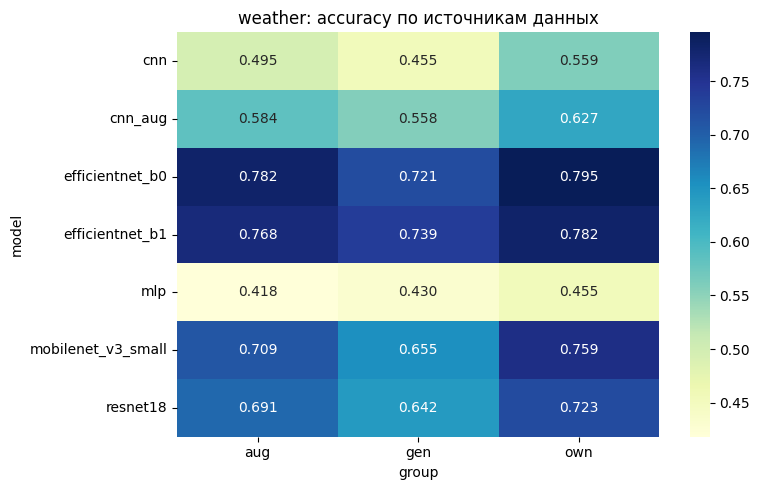

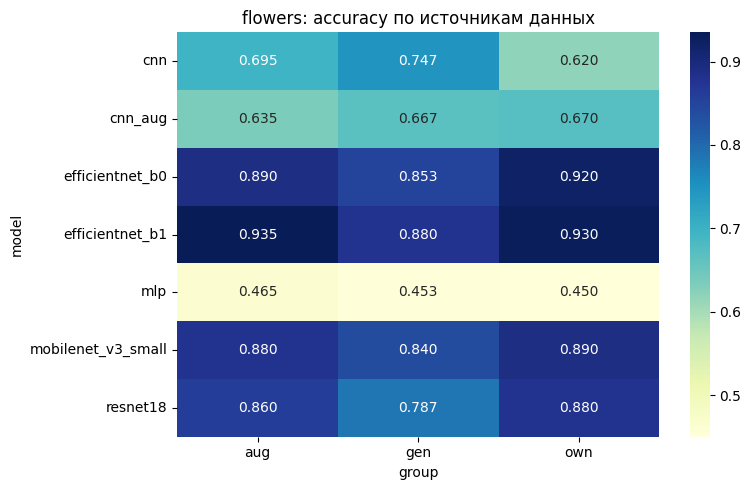

In [38]:
all_eval = pd.concat([
    own_eval_df.assign(group='own') if 'own_eval_df' in globals() else pd.DataFrame(),
    aug_eval_df.assign(group='aug') if 'aug_eval_df' in globals() else pd.DataFrame(),
    gen_eval_df.assign(group='gen') if 'gen_eval_df' in globals() else pd.DataFrame(),
], ignore_index=True)

all_eval['task'] = all_eval['source'].apply(lambda s: 'weather' if 'weather' in s else 'flowers')
summary = all_eval.pivot_table(index=['task', 'model'], columns='group', values='accuracy', aggfunc='mean').reset_index()
sort_col = 'own' if 'own' in summary.columns else summary.columns[-1]
summary = summary.sort_values(['task', sort_col], ascending=[True, False])
summary

for task_name in ['weather', 'flowers']:
    pivot = all_eval[all_eval['task'] == task_name].pivot_table(
        index='model', columns='group', values='accuracy', aggfunc='mean'
    )
    plt.figure(figsize=(8, 5))
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap='YlGnBu')
    plt.title(f'{task_name}: accuracy по источникам данных')
    plt.tight_layout()
    plt.show()

## Grad-CAM (интерпретация внимания сети)

In [42]:
class GradCAM:
    def __init__(self, model: nn.Module, target_layer: nn.Module):
        self.model = model
        self.gradients = None
        self.activations = None
        # Хуки для сохранения активаций и градиентов target слоя
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def __call__(self, x: torch.Tensor, class_idx: int | None = None):
        self.model.eval()
        x = x.to(DEVICE).requires_grad_(True)
        out = self.model(x)
        # Если класс не задан, берем предсказанный
        if class_idx is None:
            class_idx = out.argmax(1).item()
        self.model.zero_grad()
        out[0, class_idx].backward()

        # Веса CAM = среднее градиентов по spatial-размерам
        w = self.gradients.mean(dim=[2, 3], keepdim=True)
        cam = (w * self.activations).sum(dim=1).squeeze().cpu().numpy()
        cam = np.maximum(cam, 0)
        cam = cam - cam.min()
        if cam.max() > 0:
            cam = cam / cam.max()
        return cam, class_idx


def find_target_layer(model: nn.Module):
    if isinstance(model, nn.Sequential):
        return None
    if hasattr(model, 'layer4'):  # ResNet
        return model.layer4[-1]
    if hasattr(model, 'features'):  # MobileNet/EfficientNet
        return model.features[-1]
    return None


def overlay_cam(img: Image.Image, cam: np.ndarray, alpha: float = 0.45):
    w, h = img.size
    cam_img = Image.fromarray((cam * 255).astype(np.uint8)).resize((w, h))
    cam_arr = np.array(cam_img) / 255.0
    heatmap = plt.cm.jet(cam_arr)[:, :, :3]
    img_arr = np.array(img) / 255.0
    out = np.clip((1 - alpha) * img_arr + alpha * heatmap, 0, 1)
    return out


def show_gradcam_samples(
    models_dict: dict,
    classes: list[str],
    dataset: FolderWithPaths,
    model_name: str,
    n: int = 6,
    source_label: str = 'источник не задан',
):
    model = models_dict[model_name]
    layer = find_target_layer(model)
    if layer is None:
        print(f'Grad-CAM пропущен для {model_name} (нет подходящего conv target layer).')
        return

    cam_engine = GradCAM(model, layer)
    idxs = random.sample(range(len(dataset)), min(n, len(dataset)))

    fig, axes = plt.subplots(len(idxs), 3, figsize=(10, 3 * len(idxs)))
    if len(idxs) == 1:
        axes = np.array([axes])

    for r, idx in enumerate(idxs):
        x, y, path = dataset[idx]
        img = Image.open(path).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
        cam, pred = cam_engine(x.unsqueeze(0))
        ov = overlay_cam(img, cam)

        axes[r, 0].imshow(img)
        axes[r, 0].set_title(f'True: {classes[y]} | {source_label}')
        axes[r, 1].imshow(plt.cm.jet(cam)[:, :, :3])
        axes[r, 1].set_title(f'Pred: {classes[pred]}')
        axes[r, 2].imshow(ov)
        axes[r, 2].set_title(f'Overlay | {Path(path).name}')

        for c in range(3):
            axes[r, c].axis('off')

    plt.suptitle(f'Grad-CAM — {model_name} | {source_label}', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()


weather best: efficientnet_b0 | contrast: resnet18
Источник: из датасета | samples=6862


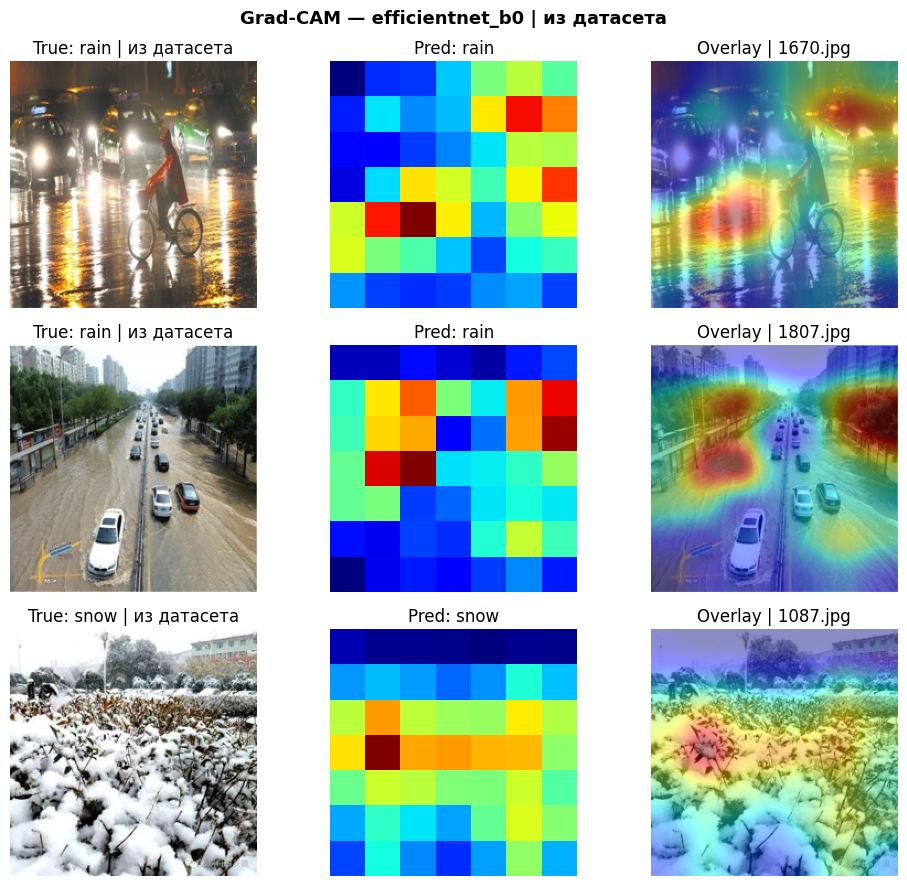

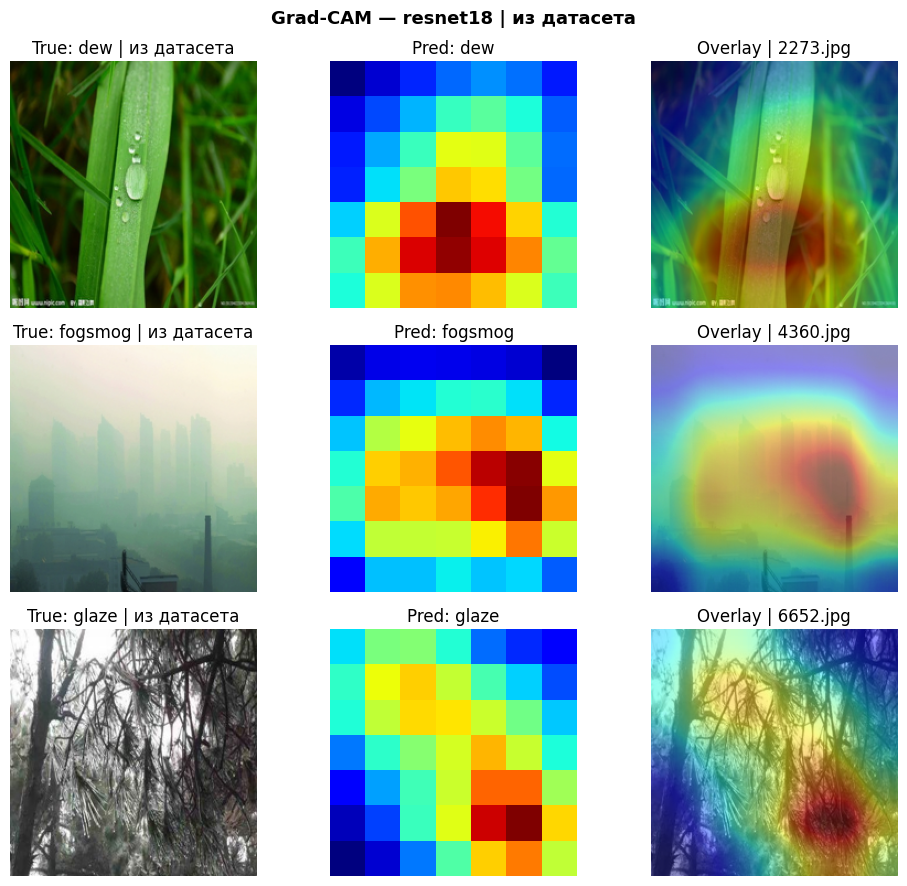

Источник: загруженные в папку own | samples=220


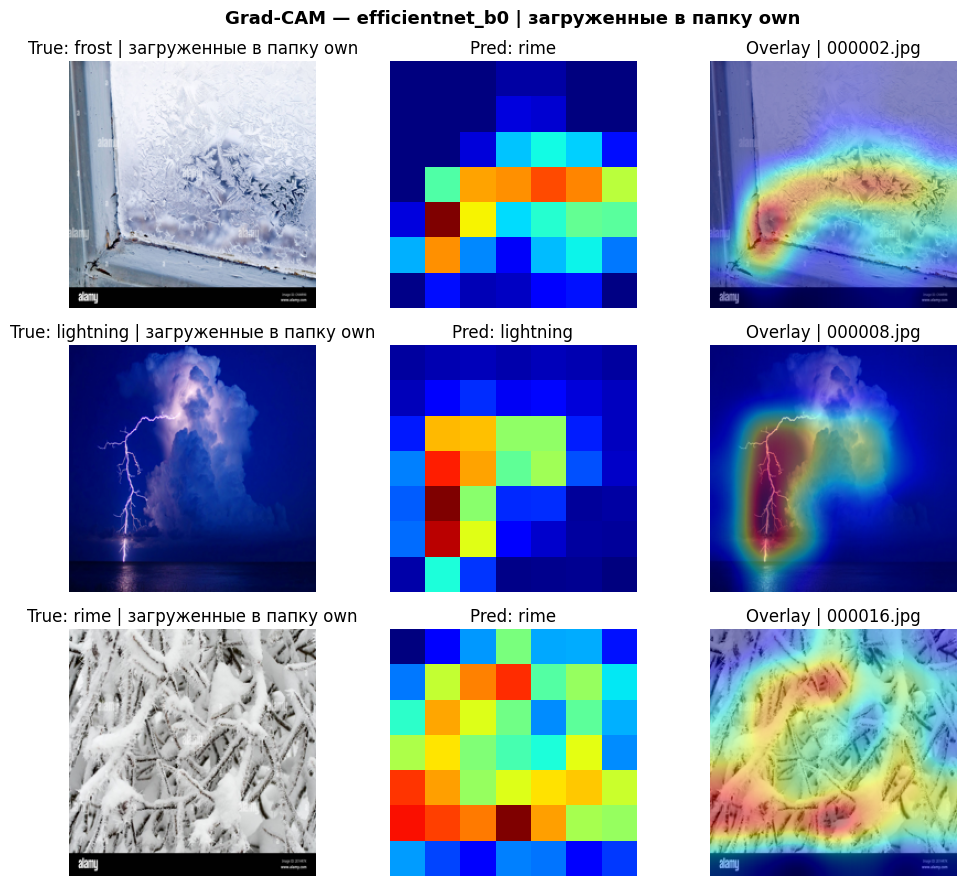

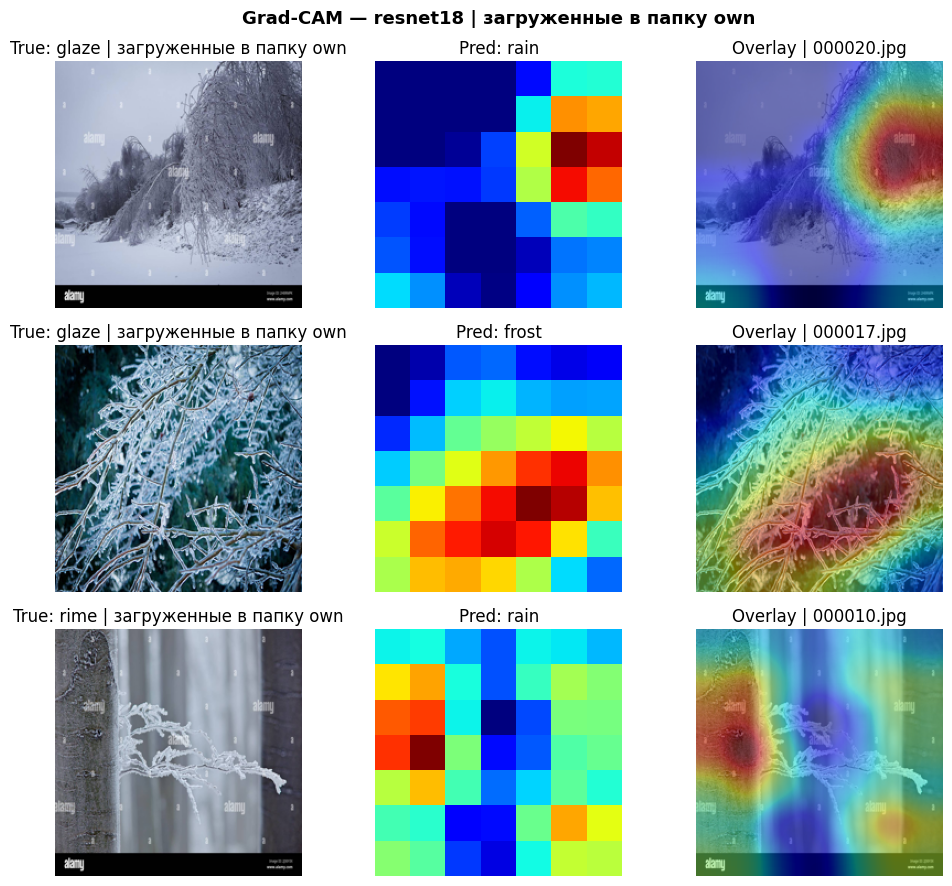

Источник: аугментированные (aug) | samples=440


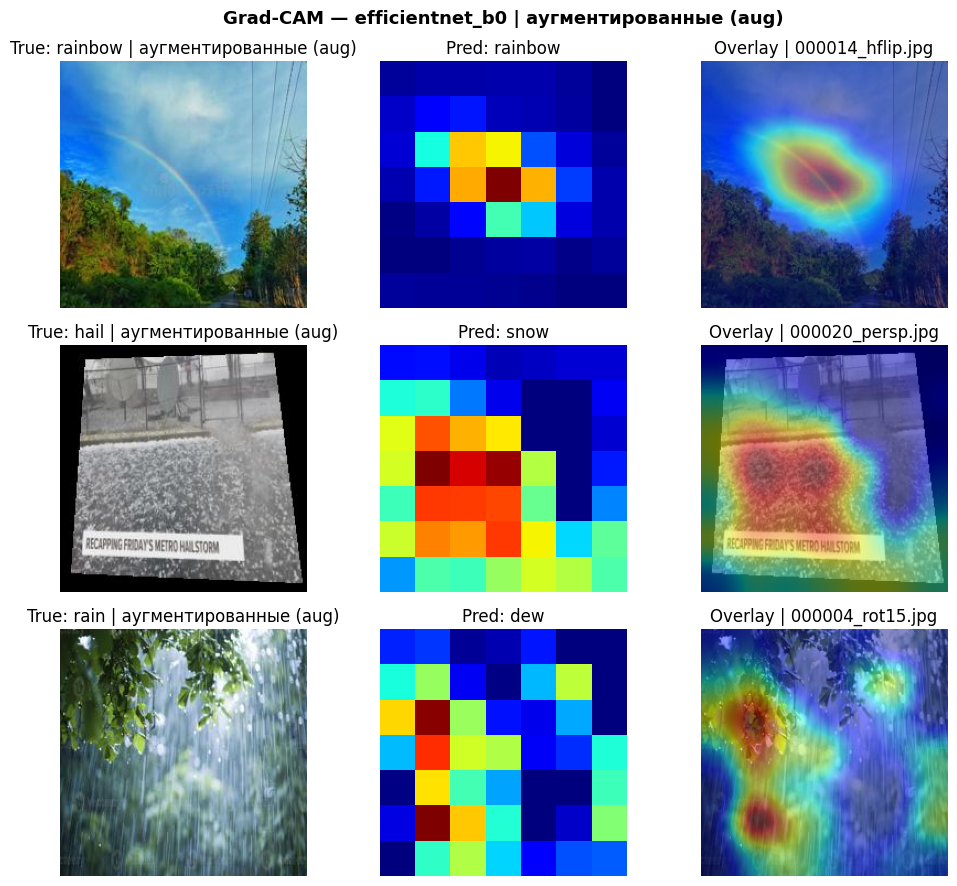

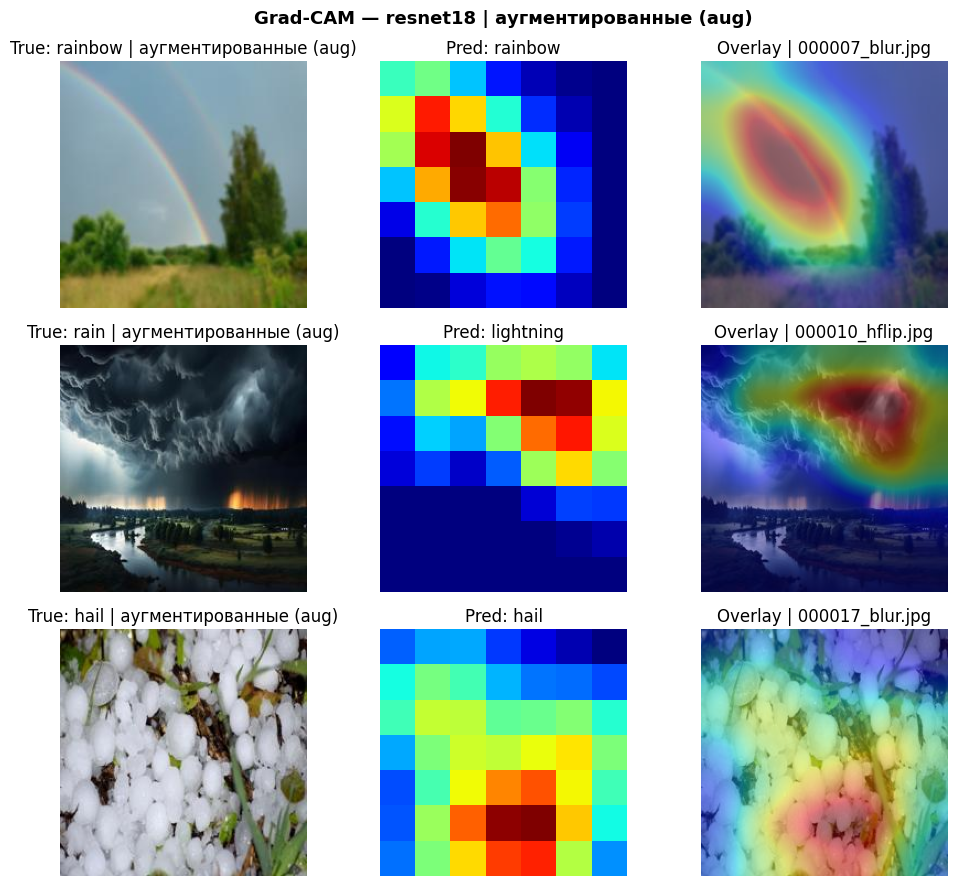

Источник: сгенерированные нейросетью | samples=165


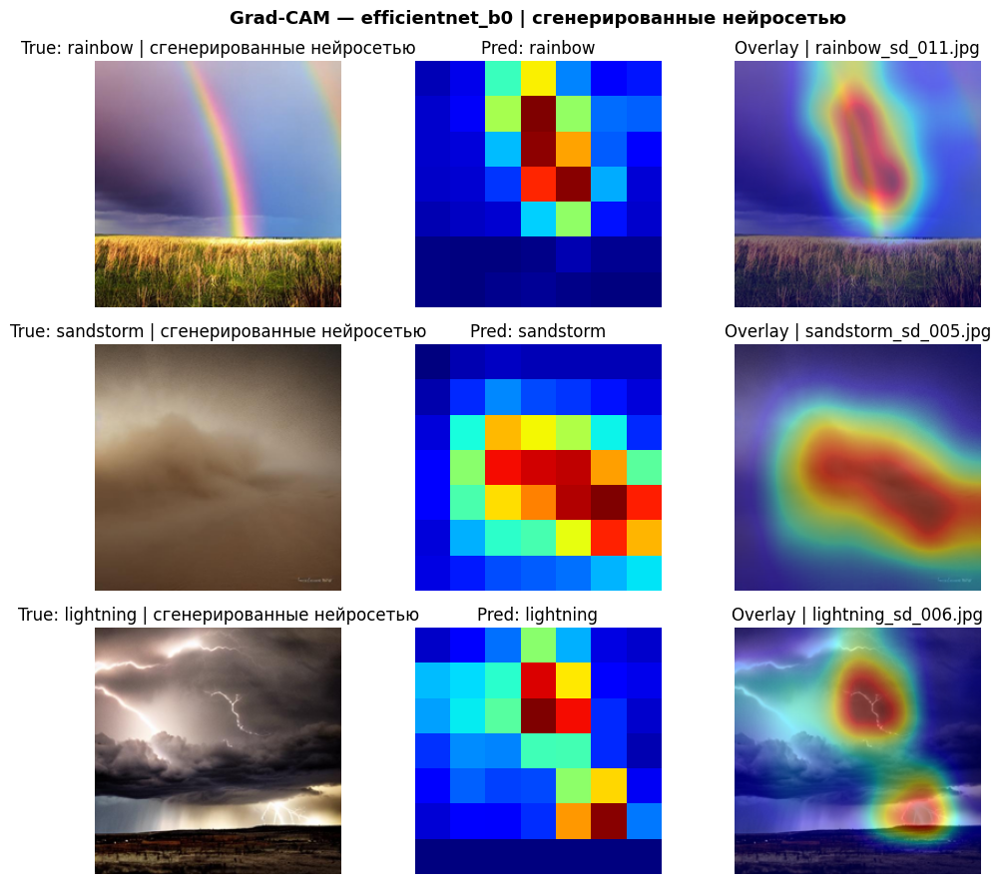

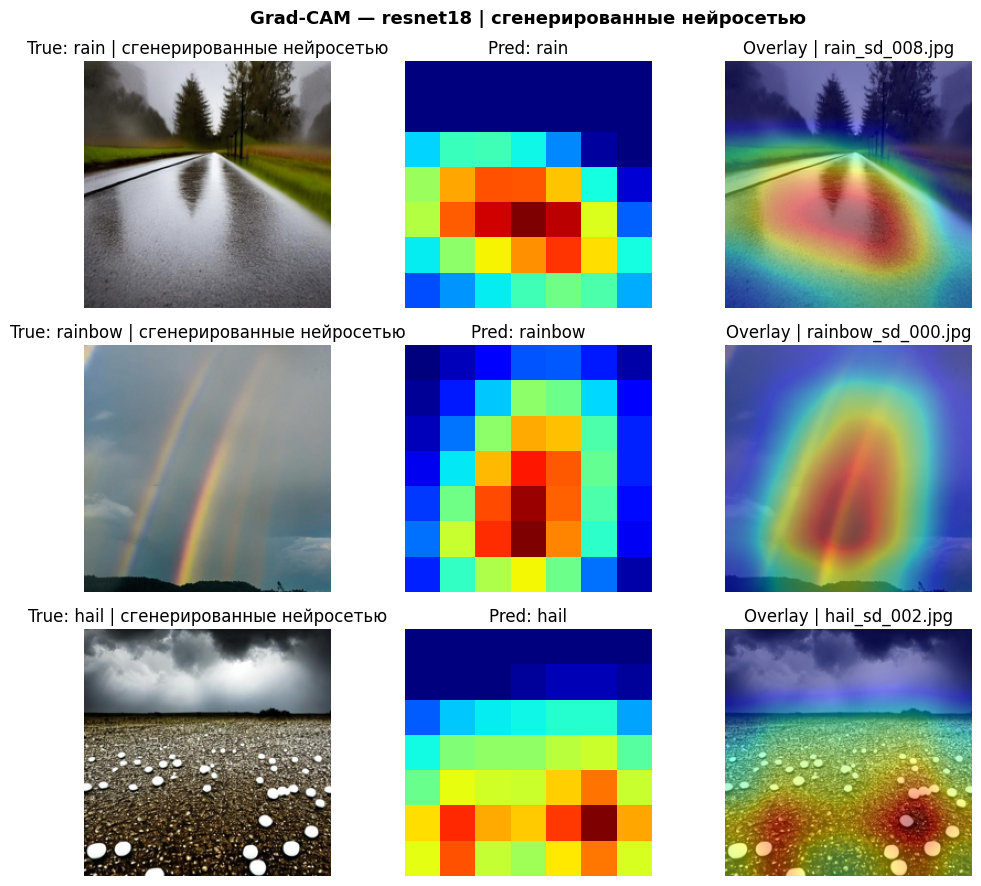

flowers best: efficientnet_b1 | contrast: resnet18
Источник: из датасета | samples=4317


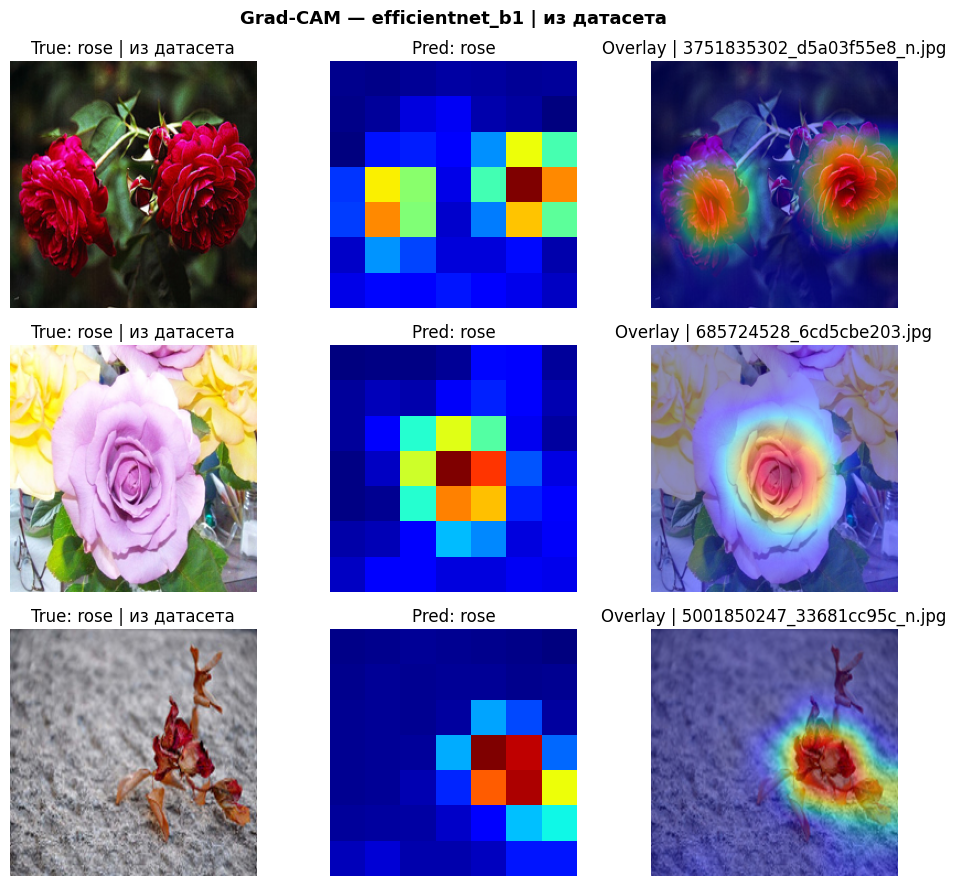

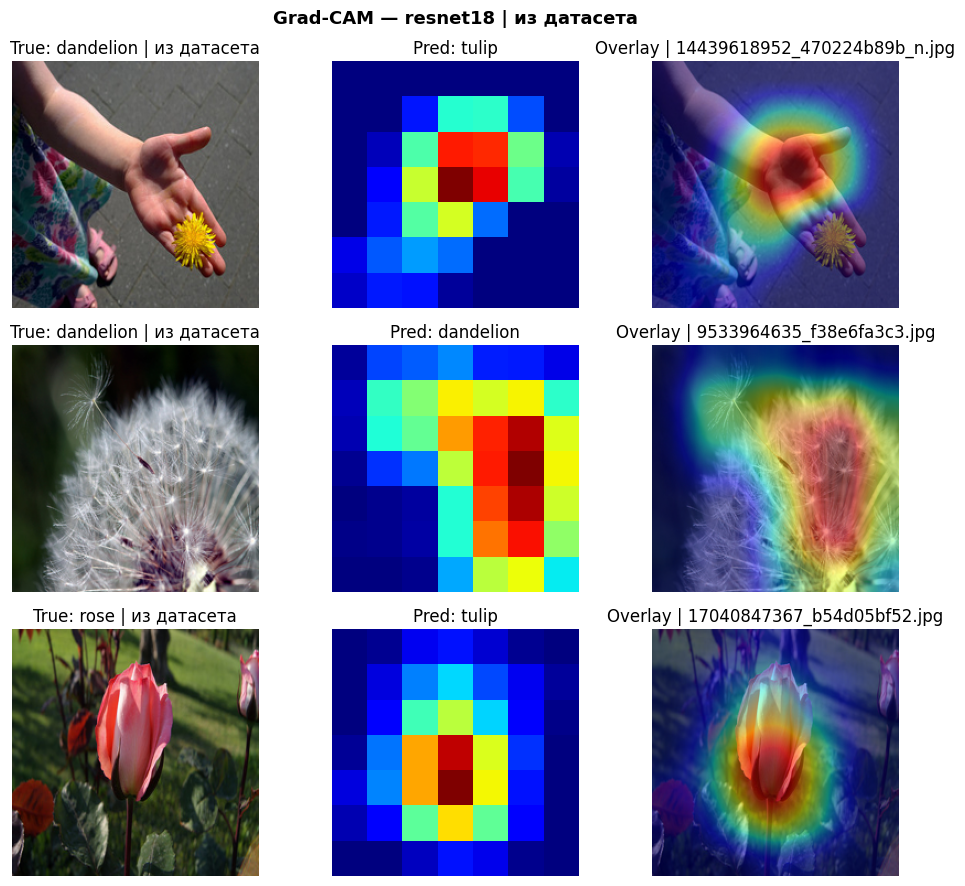

Источник: загруженные в папку own | samples=100


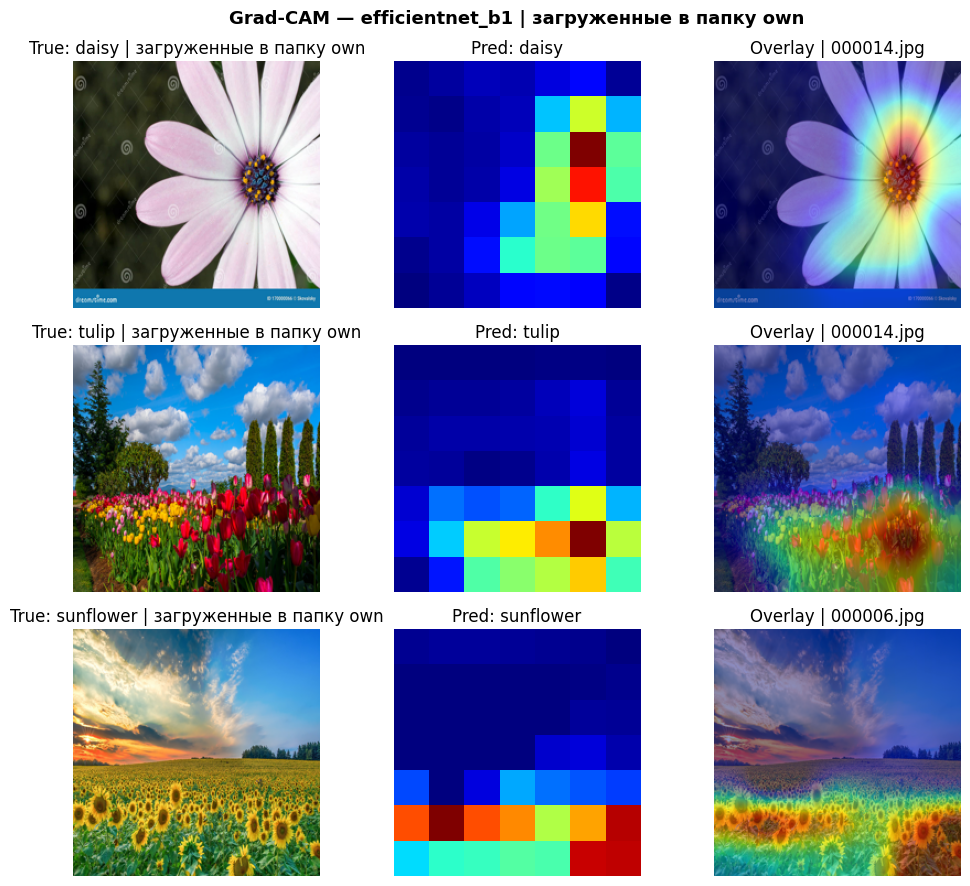

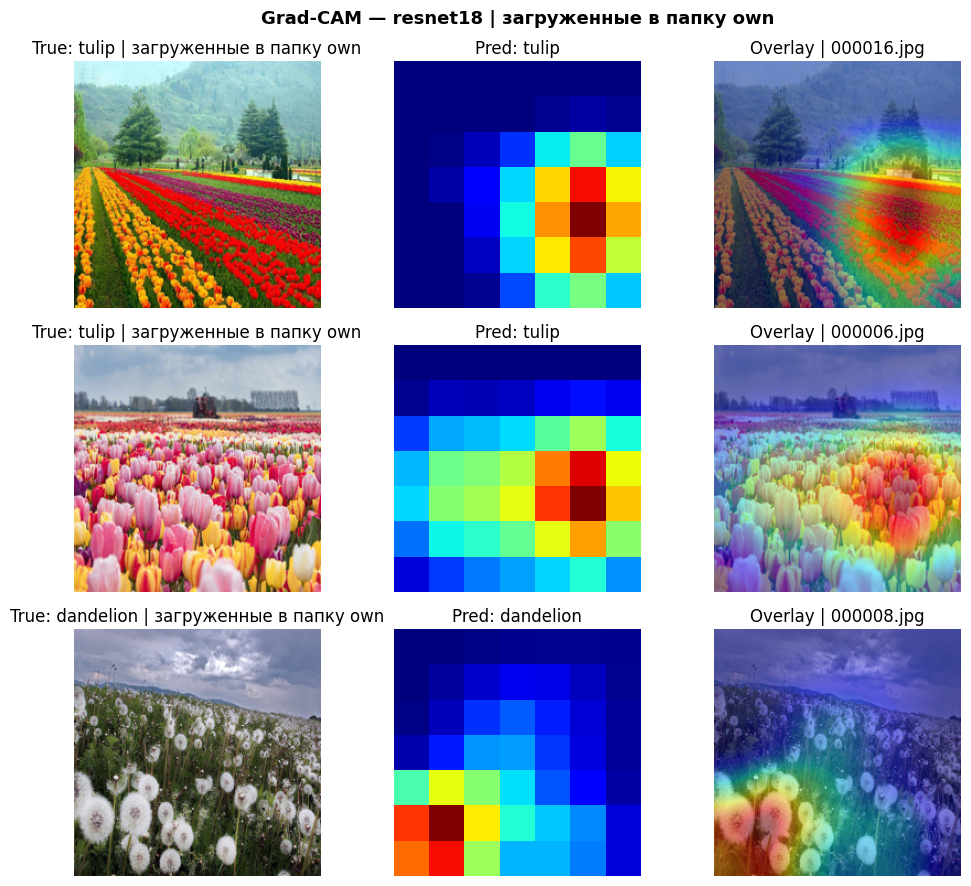

Источник: аугментированные (aug) | samples=200


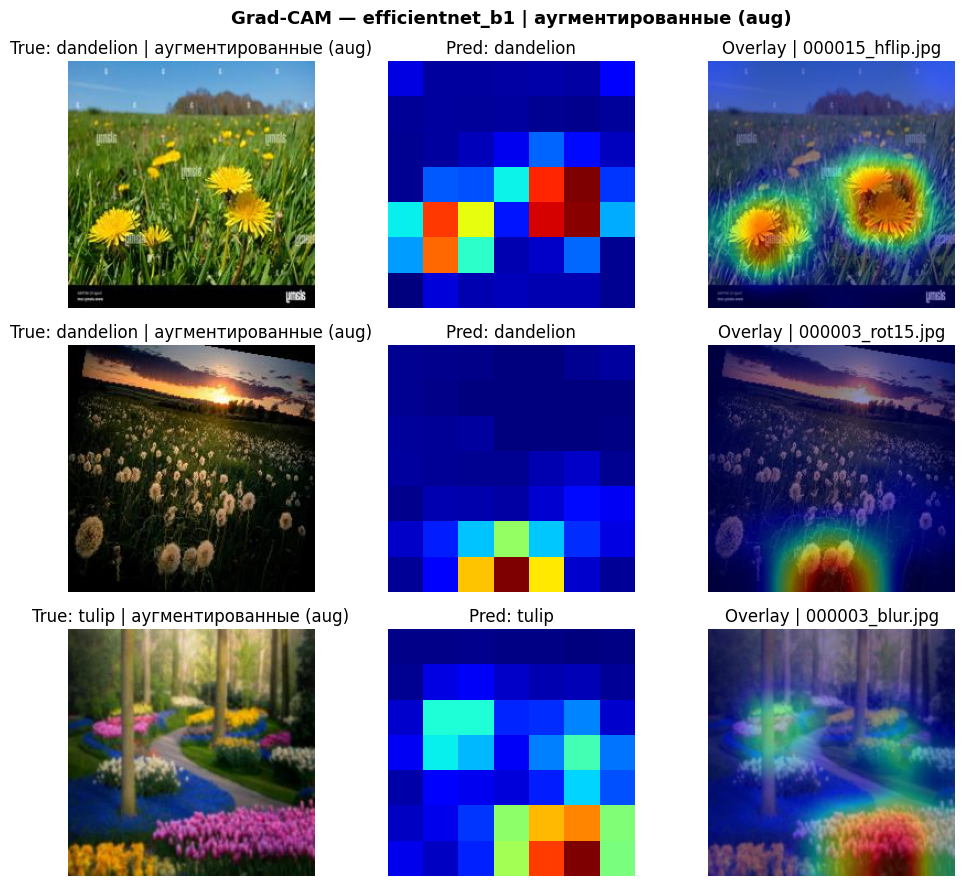

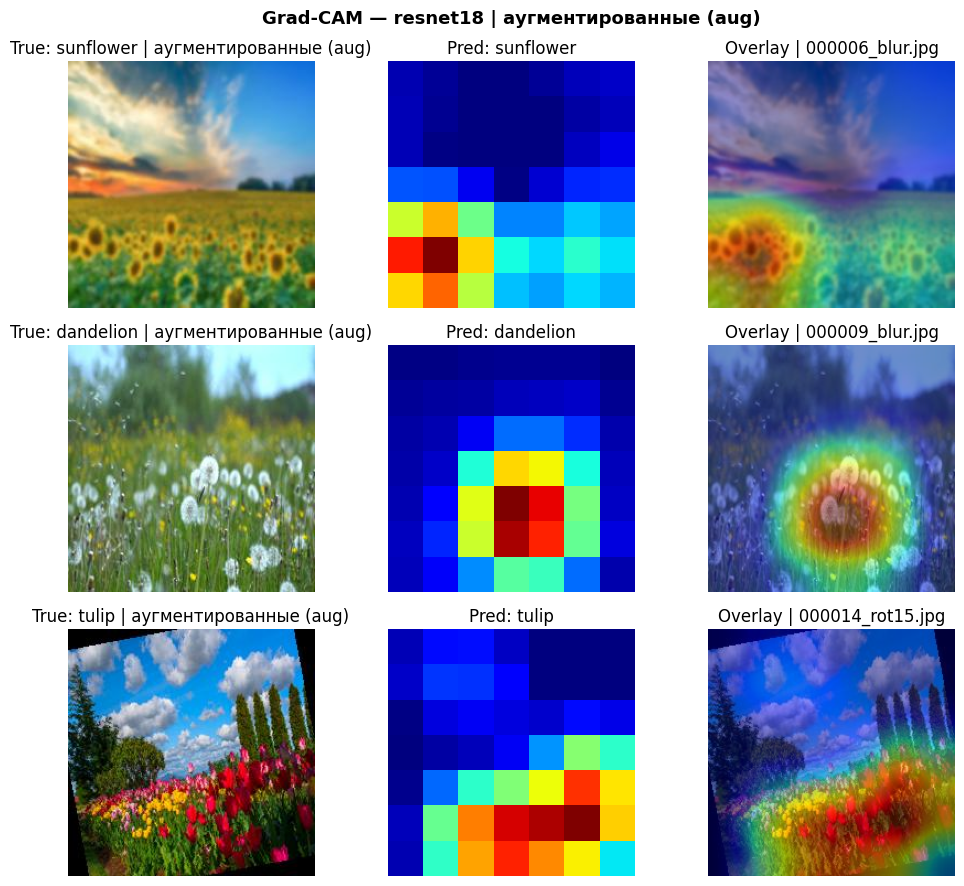

Источник: сгенерированные нейросетью | samples=75


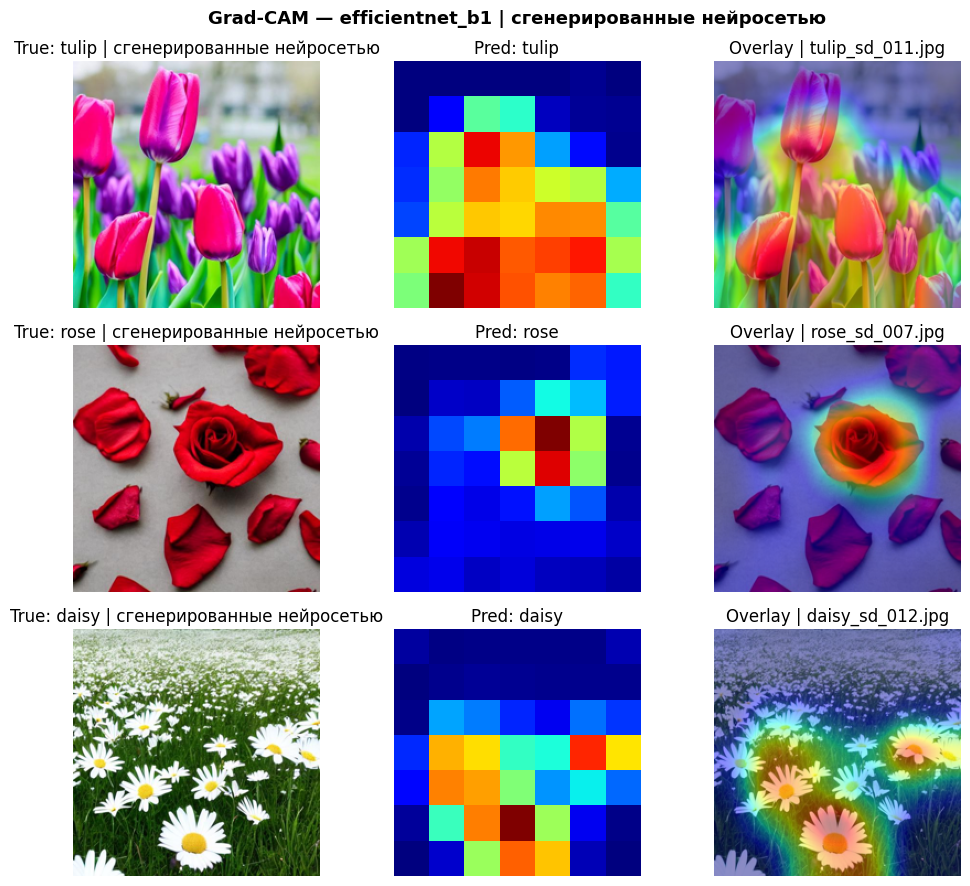

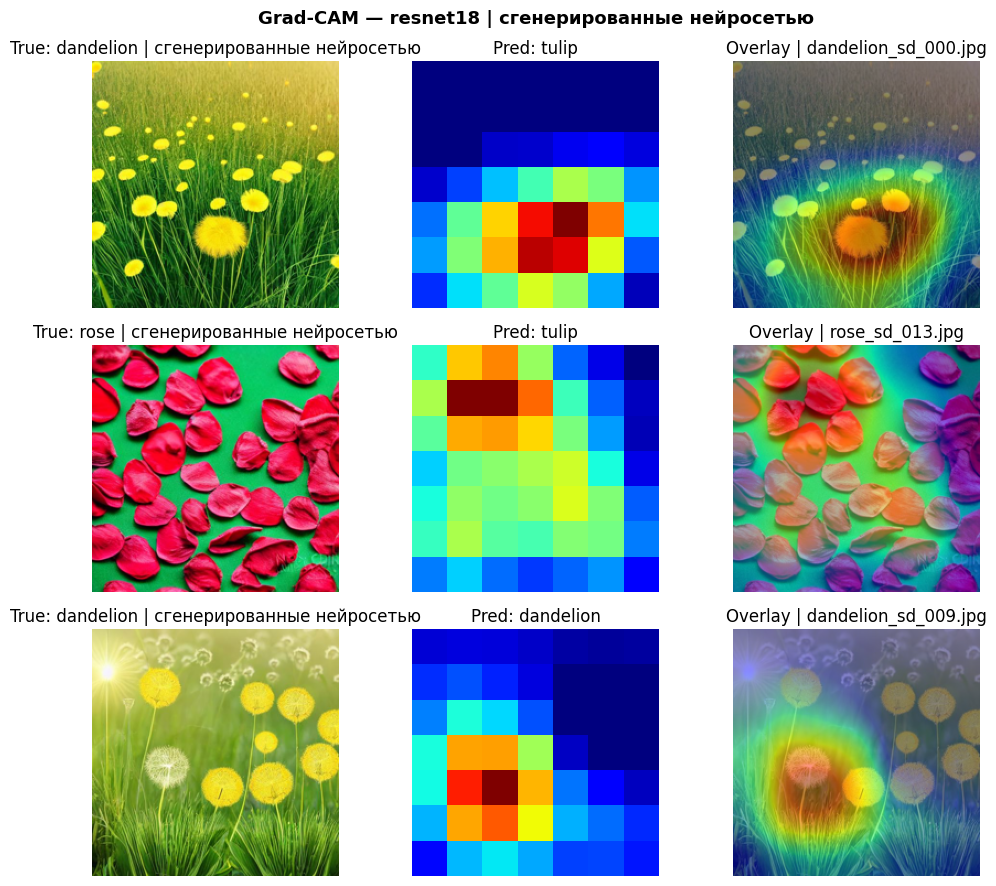

In [43]:
def pick_best_and_contrast(eval_df: pd.DataFrame, task: str, preferred_group: str = 'own'):
    df = eval_df[eval_df['task'] == task].copy()
    if df.empty:
        return None, None

    if preferred_group in df['group'].unique():
        df = df[df['group'] == preferred_group]

    # Grad-CAM применяем только к архитектурам с conv backbone
    allowed = {'resnet18', 'mobilenet_v3_small', 'efficientnet_b0', 'efficientnet_b1'}
    df = df[df['model'].isin(allowed)]
    if df.empty:
        return None, None

    best = df.sort_values('accuracy', ascending=False).iloc[0]['model']
    contrast = df.sort_values('accuracy', ascending=True).iloc[0]['model']
    return best, contrast


def build_source_datasets(task: str, classes: list[str]):
    sources = []

    # 1) Источник: исходный датасет из задания
    if task == 'weather':
        ds_base = FolderWithPaths(WEATHER_DIR, classes, transform=base_transform)
    else:
        ds_base = FolderWithPaths(FLOWERS_DIR, classes, transform=base_transform)
    if len(ds_base) > 0:
        sources.append(('из датасета', ds_base))

    # 2) Источник: фото, загруженные в own/*
    own_var = f'own_{task}_ds'
    if own_var in globals() and globals()[own_var] is not None and len(globals()[own_var]) > 0:
        sources.append(('загруженные в папку own', globals()[own_var]))

    # 3) Источник: аугментированные
    aug_var = f'aug_{task}_ds'
    if aug_var in globals() and globals()[aug_var] is not None and len(globals()[aug_var]) > 0:
        sources.append(('аугментированные (aug)', globals()[aug_var]))

    # 4) Источник: сгенерированные нейросетью
    gen_var = f'gen_{task}_ds'
    if gen_var in globals() and globals()[gen_var] is not None and len(globals()[gen_var]) > 0:
        sources.append(('сгенерированные нейросетью', globals()[gen_var]))

    return sources


def run_gradcam_for_task(task: str, models_dict: dict, classes: list[str], n_per_source: int = 3):
    if 'all_eval' not in globals() or all_eval.empty:
        print(f'Нет all_eval для task={task}, Grad-CAM пропущен.')
        return

    b, c = pick_best_and_contrast(all_eval, task, preferred_group='own')
    print(f'{task} best:', b, '| contrast:', c)

    models_to_show = []
    if b:
        models_to_show.append(b)
    if c and c != b:
        models_to_show.append(c)

    if not models_to_show:
        print(f'Нет подходящих моделей для Grad-CAM по task={task}.')
        return

    sources = build_source_datasets(task, classes)
    if not sources:
        print(f'Нет доступных источников данных для task={task}.')
        return

    for source_label, ds in sources:
        print(f'Источник: {source_label} | samples={len(ds)}')
        for model_name in models_to_show:
            show_gradcam_samples(models_dict, classes, ds, model_name, n=n_per_source, source_label=source_label)


# Weather Grad-CAM (показываем из всех доступных источников)
run_gradcam_for_task('weather', weather_models, WEATHER_CLASSES, n_per_source=3)

# Flowers Grad-CAM (показываем из всех доступных источников)
run_gradcam_for_task('flowers', flowers_models, FLOWERS_CLASSES, n_per_source=3)
